# Cas Kaggle · Despesa mèdica facturada

**Pregunta.** Amb les característiques disponibles, fins a quin punt podem estimar el cost individual facturat (`charges`)? És una regressió supervisada sobre [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance). El cost facturat no és una prima d'assegurança ni una recomanació clínica.

Fem servir edat (anys), IMC, nombre de dependents, sexe registrat, indicador de tabaquisme i regió. El CSV no inclou identificador personal ni data. Els patrons que hi veiem són associacions dins d'aquesta mostra.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
num = ['age', 'bmi', 'children']
cat = ['sex', 'smoker', 'region']
target = 'charges'
raw = pd.read_csv(Path('insurance.csv'))
assert raw.shape == (1338, 7) and set(raw.columns) == set(num + cat + [target])
assert raw[target].notna().all()
data = raw.drop_duplicates().reset_index(drop=True)
X = data[num + cat]
y = data[target]
# Keep identical explanatory profiles together even when their charges differ.
groups = pd.util.hash_pandas_object(X, index=False)
train, test = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(X, y, groups))
assert set(groups.iloc[train]).isdisjoint(groups.iloc[test])
Xtr, ytr = X.iloc[train], y.iloc[train]
eda = Xtr.assign(charges=ytr)
print({'rows_original': len(raw), 'exact_duplicates': len(raw)-len(data),
       'train': len(train), 'test_reserved': len(test)})
display(pd.DataFrame({'tipus': eda.dtypes.astype(str), 'absents_train': eda.isna().sum(),
                      'valors_distints_train': eda.nunique()}))

{'rows_original': 1338, 'exact_duplicates': 1, 'train': 1070, 'test_reserved': 267}


,tipus,absents_train,valors_distints_train
age,int64,0,47
bmi,float64,0,502
children,int64,0,6
sex,str,0,2
smoker,str,0,2
region,str,0,4
charges,float64,0,1070


## 1. Exploració sobre entrenament

Retirem la còpia exacta perquè no aporti una observació repetida. Si hi ha perfils de predictors idèntics, els mantenim junts per evitar que un mateix perfil aparegui a entrenament i validació o test. Sense identificadors no podem detectar persones repetides amb perfils diferents. Reservem el test abans de l'exploració. Els zeros de dependents són vàlids. El CSV original es conserva intacte al repositori.

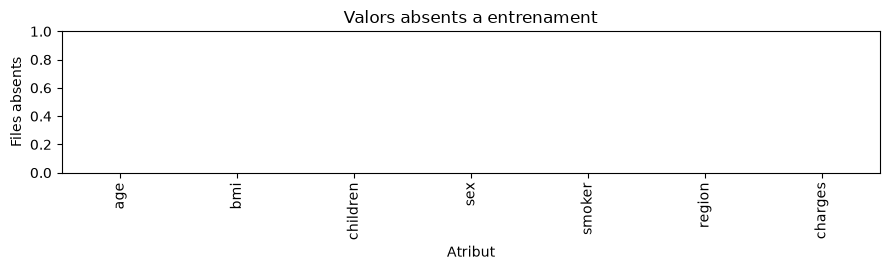

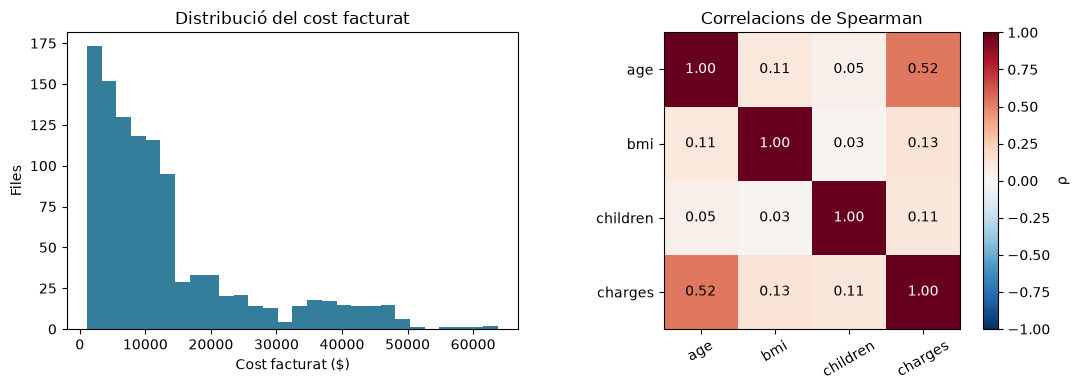

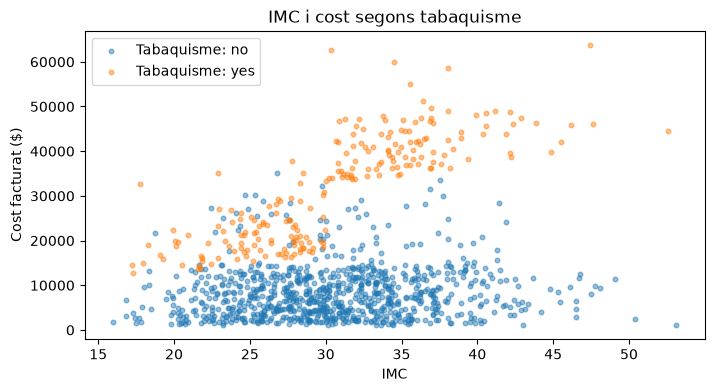

,count,median,mean
smoker,,,
no,854,7331.40,8391.33
yes,216,34278.61,31897.85


La distribució té cua dreta: mediana **9,289 $** i mitjana **13,137 $**. El tabaquisme separa grups amb costos diferents; el gràfic suggereix que la relació amb l’IMC pot variar per grup. La correlació bivariada no captura bé interaccions ni estableix causalitat. No hi ha absències a entrenament. La imputació al pipeline és una política explícita per a entrades futures i s’ajusta dins de cada fold.

In [2]:
fig, ax = plt.subplots(figsize=(9, 2.8))
eda.isna().sum().plot.bar(ax=ax, color='#347d9b')
ax.set(title='Valors absents a entrenament', ylabel='Files absents', xlabel='Atribut', ylim=(0, 1))
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(ytr, bins=28, color='#347d9b')
axes[0].set(title='Distribució del cost facturat', xlabel='Cost facturat ($)', ylabel='Files')
corr = eda[num + [target]].corr(method='spearman')
im = axes[1].imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
axes[1].set_xticks(range(len(corr)), corr.columns, rotation=30)
axes[1].set_yticks(range(len(corr)), corr.columns)
axes[1].set_title('Correlacions de Spearman')
for i in range(len(corr)):
    for j in range(len(corr)):
        axes[1].text(j, i, f'{corr.iat[i,j]:.2f}', ha='center', va='center',
                     color='white' if abs(corr.iat[i,j]) > .7 else 'black')
fig.colorbar(im, ax=axes[1], label='ρ')
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
for level, rows in eda.groupby('smoker'):
    ax.scatter(rows.bmi, rows.charges, s=11, alpha=.48, label=f'Tabaquisme: {level}')
ax.set(title='IMC i cost segons tabaquisme', xlabel='IMC', ylabel='Cost facturat ($)')
ax.legend()
plt.show()
display(eda.groupby('smoker')[target].agg(['count','median','mean']).round(2))
display(Markdown(f'La distribució té cua dreta: mediana **{ytr.median():,.0f} $** i mitjana '
                 f'**{ytr.mean():,.0f} $**. El tabaquisme separa grups amb costos diferents; '
                 'el gràfic suggereix que la relació amb l’IMC pot variar per grup. '
                 'La correlació bivariada no captura bé interaccions ni estableix causalitat. '
                 'No hi ha absències a entrenament. La imputació al pipeline és una política explícita '
                 'per a entrades futures i s’ajusta dins de cada fold.'))

## 2. Baseline, quatre models i cerca d'hiperparàmetres

La baseline constant prediu la mediana, que minimitza l'error absolut entre prediccions constants. La mètrica principal és MAE en dòlars. RMSE i R² complementen la lectura de test: la primera penalitza errors grans i la segona compara amb l'escala de variació del target.

Comparem Ridge (regressió lineal amb penalització L2), KNN (cost local dels perfils veïns), Random Forest (mitjana d'arbres construïts sobre mostres diferents) i Gradient Boosting (arbres petits ajustats seqüencialment als errors). Els dos últims poden representar interaccions. La mediana, l'escalat i el one-hot s'ajusten dins de cada fold. Tots els models tenen els mateixos cinc folds agrupats. Triem el menor MAE mitjà de validació creuada i reajustem aquella configuració amb tot l'entrenament.

,model,MAE_CV,SD_folds,configuracions,millors_paràmetres
3,Random Forest,2476.466690,193.598718,9,"{'randomforestregressor__max_depth': 8, 'rando..."
4,Gradient Boosting,2478.985660,181.541870,8,{'gradientboostingregressor__learning_rate': 0...
2,KNN,3372.181575,117.934212,6,"{'kneighborsregressor__n_neighbors': 5, 'kneig..."
1,Ridge,4165.643139,299.905779,5,{'ridge__alpha': 0.01}
0,Baseline (mediana),8236.189695,643.596733,1,{}


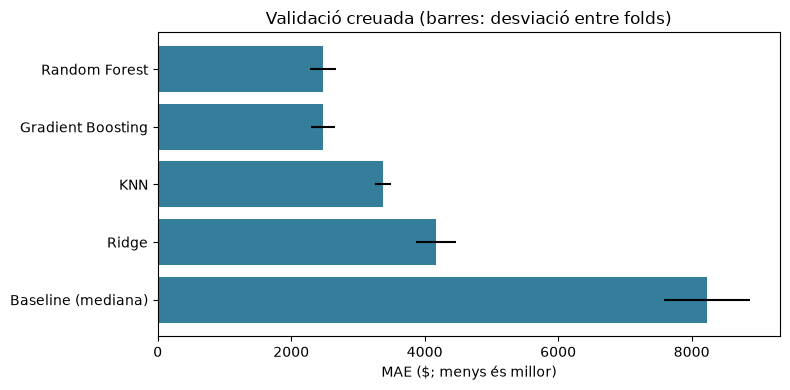

Model fixat abans de test: **Random Forest**. Les barres mostren dispersió descriptiva, no intervals de confiança. El millor resultat de CV ja incorpora la cerca de paràmetres i pot ser optimista; el test reservat dona l’avaluació final.

In [3]:
prep = ColumnTransformer([
    ('numerics', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
    ('categories', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat),
])
specs = {
    'Baseline (mediana)': (DummyRegressor(strategy='median'), {}),
    'Ridge': (Ridge(), {'ridge__alpha': [.01, .1, 1, 10, 100]}),
    'KNN': (KNeighborsRegressor(), {'kneighborsregressor__n_neighbors': [5, 15, 30],
                                    'kneighborsregressor__weights': ['uniform', 'distance']}),
    'Random Forest': (RandomForestRegressor(n_estimators=120, random_state=SEED),
                      {'randomforestregressor__max_depth': [4, 8, None],
                       'randomforestregressor__min_samples_leaf': [2, 5, 12]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=SEED),
                          {'gradientboostingregressor__max_depth': [2, 3],
                           'gradientboostingregressor__n_estimators': [60, 120],
                           'gradientboostingregressor__learning_rate': [.03, .08]}),
}
cv = list(GroupKFold(n_splits=5).split(Xtr, ytr, groups.iloc[train]))
fitted, rows = {}, []
for label, (estimator, grid) in specs.items():
    search = GridSearchCV(make_pipeline(prep, estimator), grid, cv=cv,
                          scoring='neg_mean_absolute_error', error_score='raise')
    search.fit(Xtr, ytr)
    fitted[label] = search
    rows.append({'model': label, 'MAE_CV': -search.best_score_,
                 'SD_folds': search.cv_results_['std_test_score'][search.best_index_],
                 'configuracions': len(search.cv_results_['params']),
                 'millors_paràmetres': search.best_params_})
comparison = pd.DataFrame(rows).sort_values('MAE_CV')
display(comparison)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(comparison.model, comparison.MAE_CV, xerr=comparison.SD_folds, color='#347d9b')
ax.invert_yaxis()
ax.set(title='Validació creuada (barres: desviació entre folds)', xlabel='MAE ($; menys és millor)')
plt.tight_layout()
plt.show()
winner = comparison.iloc[0].model
display(Markdown(f'Model fixat abans de test: **{winner}**. Les barres mostren dispersió descriptiva, '
                 'no intervals de confiança. El millor resultat de CV ja incorpora la cerca de '
                 'paràmetres i pot ser optimista; el test reservat dona l’avaluació final.'))

## 3. Test final i errors

Fem una sola predicció del model seleccionat. Mesurem el signe del residu com a predicció menys observat. Desglossem errors per tabaquisme i sexe registrat sobre aquestes mateixes prediccions. Són resultats descriptius, amb composicions de grup diferents.

model              Random Forest
MAE                  2623.710359
RMSE                 4789.273809
R2                      0.853017
baseline_CV_MAE      8236.189695
winner_CV_MAE         2476.46669
dtype: object

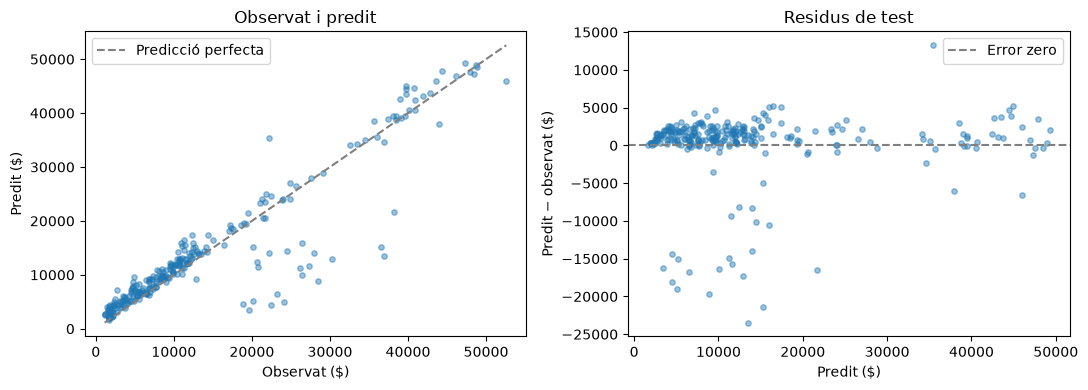

,n,MAE,biaix
smoker,,,
no,209,2751.83,-63.28
yes,58,2162.04,668.85


,n,MAE,biaix
sex,,,
female,129,2507.68,-73.69
male,138,2732.17,254.15


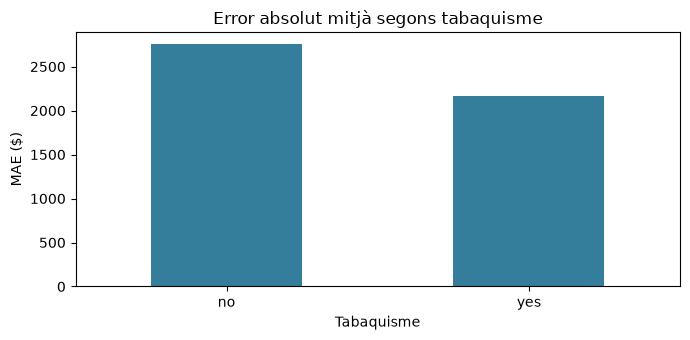

,age,smoker,observat,prediccio,residu
1205,59,no,36910.61,13447.41,-23463.20
461,42,yes,22144.03,35410.37,13266.34


En test el MAE és **2,624 $** i el RMSE **4,789 $**. Els casos extrems de la taula mostren què pot amagar el MAE global. Per tabaquisme, el MAE és **2,162 $** (sí) i **2,752 $** (no). Comparem aquests grups amb les seves mides i rangs de cost; aquesta diferència no estableix discriminació ni causalitat.

In [4]:
Xte, yte = X.iloc[test], y.iloc[test]
pred = fitted[winner].predict(Xte)
audit = Xte.assign(observat=yte, prediccio=pred)
audit['residu'] = audit.prediccio - audit.observat
audit['error_absolut'] = audit.residu.abs()
metrics = {'model': winner, 'MAE': mean_absolute_error(yte, pred),
           'RMSE': root_mean_squared_error(yte, pred), 'R2': r2_score(yte, pred)}
metrics['baseline_CV_MAE'] = -fitted['Baseline (mediana)'].best_score_
metrics['winner_CV_MAE'] = -fitted[winner].best_score_
display(pd.Series(metrics))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lo, hi = min(yte.min(), pred.min()), max(yte.max(), pred.max())
axes[0].scatter(yte, pred, alpha=.45, s=15)
axes[0].plot([lo, hi], [lo, hi], '--', color='gray', label='Predicció perfecta')
axes[0].set(title='Observat i predit', xlabel='Observat ($)', ylabel='Predit ($)')
axes[0].legend()
axes[1].scatter(pred, audit.residu, alpha=.45, s=15)
axes[1].axhline(0, linestyle='--', color='gray', label='Error zero')
axes[1].set(title='Residus de test', xlabel='Predit ($)', ylabel='Predit − observat ($)')
axes[1].legend()
plt.tight_layout()
plt.show()
summaries = {}
for col in ['smoker', 'sex']:
    summaries[col] = audit.groupby(col).agg(n=('residu','size'), MAE=('error_absolut','mean'),
                                            biaix=('residu','mean'))
    display(summaries[col].round(2))
fig, ax = plt.subplots(figsize=(7, 3.5))
summaries['smoker'].MAE.plot.bar(ax=ax, color='#347d9b', rot=0)
ax.set(title='Error absolut mitjà segons tabaquisme', xlabel='Tabaquisme', ylabel='MAE ($)')
plt.tight_layout()
plt.show()
display(audit.sort_values('residu').iloc[[0, -1]][['age','smoker','observat','prediccio','residu']].round(2))
by_smoker = summaries['smoker']
display(Markdown(f'En test el MAE és **{metrics["MAE"]:,.0f} $** i el RMSE '
                 f'**{metrics["RMSE"]:,.0f} $**. Els casos extrems de la taula mostren què pot '
                 'amagar el MAE global. Per tabaquisme, el MAE és '
                 f'**{by_smoker.loc["yes","MAE"]:,.0f} $** (sí) i '
                 f'**{by_smoker.loc["no","MAE"]:,.0f} $** (no). Comparem aquests grups amb les '
                 'seves mides i rangs de cost; aquesta diferència no estableix discriminació ni causalitat.'))

## 4. Límits i millores

Un ús acadèmic és comparar com s'equivoquen els models en estimar costos històrics. Falta validar en una altra població i període, mesurar incertesa i estudiar si les diferències d'error es mantenen amb dades addicionals. Els predictors són limitats i les variables personals poden reflectir desigualtats de la mostra. L'experiment no és adequat per prendre decisions reals de cobertura, preus individuals o assistència mèdica.

**Ús d'IA.** OpenAI Codex ha preparat el codi, les explicacions i les comprovacions d'aquesta versió de seguiment. Les decisions i la interpretació són propostes per revisar i defensar.